<a href="https://colab.research.google.com/github/Razan445/IT326-Project/blob/main/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [1] Problem

# Project Goal

The main objective of this project is to apply data mining techniques—specifically Classification and Clustering—on the Titanic dataset:

- Classification Task: Build Decision Tree models to predict passenger survival status (Survived).
- Clustering Task: Apply K-Means clustering to identify similar patterns and groupings among passengers based on their features.

# [2] Data  

In [1]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Raw_dataset.csv")


In [2]:
#Number of attributes
print("Number of attributes: ",df.shape[1])

#Data type of attributes
print("\nData types of attributes:")
print(df.dtypes)

Number of attributes:  12

Data types of attributes:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [3]:
#Number of objects (rows)
print("Number of objects: ",df.shape[0])

Number of objects:  891


In [4]:
#class attribute
print("class attribute: survived")

#number of classes
print("Number of classes: ",df["Survived"].nunique())

#class value and their count
print("\nClass distribution:")
print(df["Survived"].value_counts())

class attribute: survived
Number of classes:  2

Class distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [5]:
#Display a sample of row dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# [3] Data Mining Task

• Classification Task: Build Decision Tree models to predict passenger survival status (Survived).

• Clustering Task: Apply K-Means clustering to identify similar patterns and groupings among passengers based on their features.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Raw_dataset.csv')
raw_df = df.copy()

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
stat_summary = df[numeric_cols].describe().T

stat_summary['IQR'] = stat_summary['75%'] - stat_summary['25%']

print("--- Statistical and Five-Number Summaries ---")
display(stat_summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR']])

--- Statistical and Five-Number Summaries ---


,count,mean,std,min,25%,50%,75%,max,IQR
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000,445.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000,1.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000,17.8750
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000,1.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000,0.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292,23.0896


### Statistical & Five-Number Summary Interpretation
- **`Age`:** Has a mean of ~29.7 years, a median (50%) of 28 years, and an IQR of 17.75 years, showing a relatively normal concentration around adults aged 20–38.
- **`Fare`:** Has a high standard deviation (std = 49.69) with a mean of 32.20 and a maximum of 512.32, which indicates a strongly right-skewed distribution with extreme high values.

In [8]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent
})

print("--- Missing Values Summary ---")
display(missing_table[missing_table['Missing Count'] > 0])

--- Missing Values Summary ---


,Missing Count,Percentage (%)
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


### Missing Values Analysis & Preprocessing Needs
- **`Cabin`:** Contains **687 missing values (77.10%)**. Due to this high missing rate, imputation is not recommended as it may introduce noise, suggesting the attribute should be dropped.
- **`Age`:** Contains **177 missing values (19.87%)**. Since Age is an important feature, it requires imputation using central metrics (e.g., median imputed by passenger class/gender).
- **`Embarked`:** Contains only **2 missing values (0.22%)**, which can easily be imputed using the mode (most frequent port).

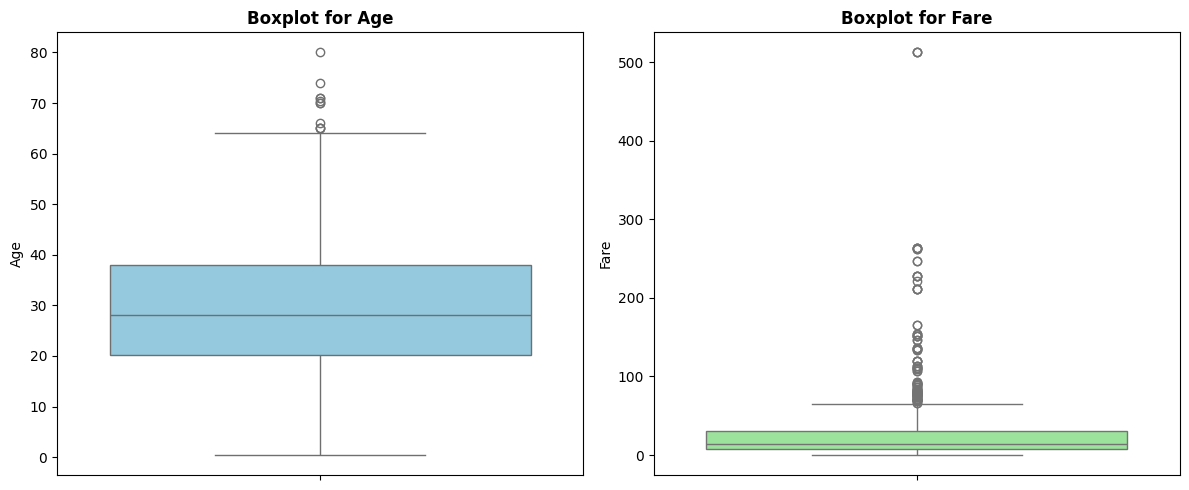

Age Outliers Count: 11 (Threshold: > 64.81)
Fare Outliers Count: 116 (Threshold: > 65.63)


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Outliers Extraction and Boxplots for Numeric Attributes
plt.figure(figsize=(12, 5))

# Boxplot for Age
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Age'], color='skyblue')
plt.title('Boxplot for Age', fontsize=12, fontweight='bold')

# Boxplot for Fare
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Fare'], color='lightgreen')
plt.title('Boxplot for Fare', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Detect Outliers programmatically using IQR
def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), lower, upper

age_outliers_cnt, age_low, age_high = detect_outliers_iqr(df['Age'].dropna())
fare_outliers_cnt, fare_low, fare_high = detect_outliers_iqr(df['Fare'].dropna())

print(f"Age Outliers Count: {age_outliers_cnt} (Threshold: > {age_high:.2f})")
print(f"Fare Outliers Count: {fare_outliers_cnt} (Threshold: > {fare_high:.2f})")

### Outliers Analysis & Need for Preprocessing
- **`Fare` Boxplot Explanation:** The plot indicates a severe presence of extreme upper outliers (116 data points above 65.63). This demonstrates that raw Fare values will skew distance-based machine learning algorithms. Thus, **normalization (such as Log Transformation or Min-Max / Standard Scaling)** is strongly needed in the preprocessing stage to handle noise and scale the data properly.
- **`Age` Boxplot Explanation:** Shows a small cluster of upper outliers (older passengers above 64.81 years). Since these are realistic historical values rather than errors, **discretization (binning ages into categorical groups)** or robust scaling can be utilized.

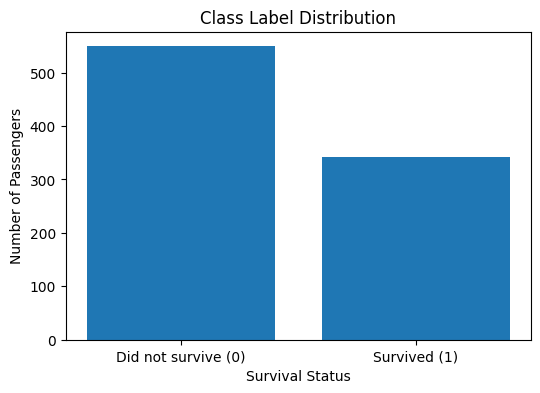

In [10]:
import matplotlib.pyplot as plt

survival_counts = df["Survived"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Did not survive (0)", "Survived (1)"],
    survival_counts.values
)

plt.title("Class Label Distribution")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

plt.show()

Description:

The bar plot shows the distribution of the target variable, Survived, in the Titanic dataset. The dataset contains 549 passengers who did not survive (0) and 342 passengers who survived (1). This indicates that the class labels are imbalanced, as the number of passengers who did not survive is higher than the number of survivors. This imbalance should be considered during data preprocessing and when evaluating the performance of classification models.


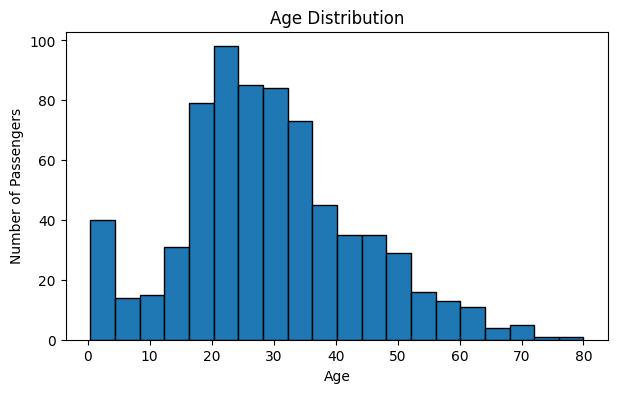

In [11]:
plt.figure(figsize=(7, 4))

plt.hist(df["Age"].dropna(), bins=20, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

Description:

The histogram shows the distribution of passengers’ ages. Most passengers were between approximately 18 and 35 years old, with the highest frequency around the early twenties. The number of passengers generally decreases at older ages, and relatively few passengers were above 60 years old. The distribution is not uniform, with more passengers concentrated in the younger and middle-age ranges. This information helps us understand the distribution of the Age attribute and consider whether further preprocessing, such as discretization, would be useful for the data mining task.


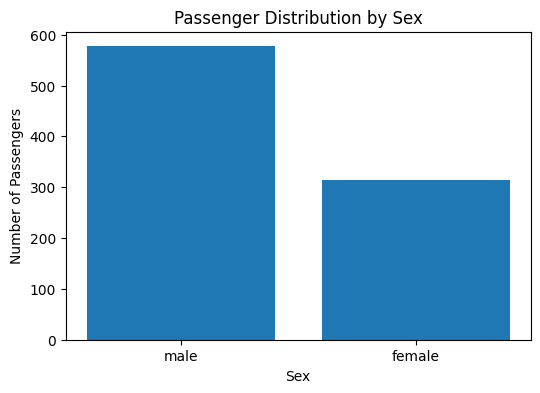

In [12]:
sex_counts = df["Sex"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(sex_counts.index, sex_counts.values)

plt.title("Passenger Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

Description:

The bar plot shows the distribution of passengers by sex. The dataset contains approximately 577 male passengers and 314 female passengers, indicating that male passengers are more numerous than female passengers. The Sex attribute is categorical and nominal, so its values need to be converted into a suitable numerical representation before being used by algorithms that require numerical input. This observation supports considering categorical encoding during the preprocessing stage.


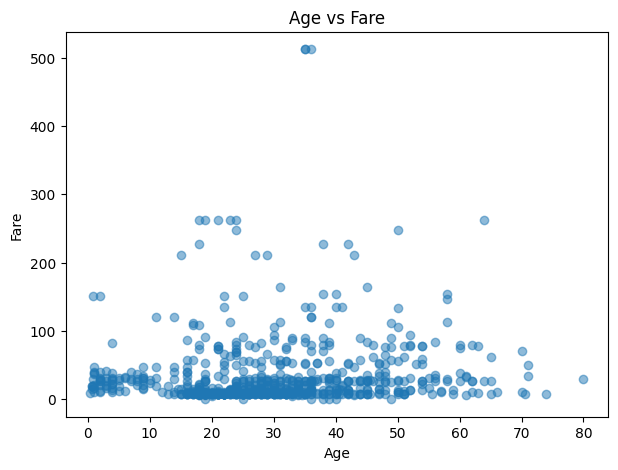

In [13]:
plt.figure(figsize=(7, 5))

plt.scatter(df["Age"], df["Fare"], alpha=0.5)

plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

Description:

The scatter plot illustrates the relationship between passengers’ ages and ticket fares. Most passengers paid fares below 50, across a wide range of ages. However, a small number of passengers paid much higher fares, including values close to 500. These extreme fare values indicate that the Fare attribute has a wide range and may contain potential outliers. This suggests that the fare distribution should be examined during preprocessing, and normalization or other suitable techniques may be considered if needed for the data mining algorithms.

In [14]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Raw_dataset.csv")


###Data Preprocessing – Technique 1: Cleaning & Noise Removal
In this section, missing values were handled and outliers were treated so the dataset is clean and ready for the next preprocessing steps.

In [15]:
# ===== 1. Snapshot of the raw dataset =====

print("Shape:", df.shape)

display(df.head(10))



# ===== 2. Work on a copy (raw stays untouched) =====

df_clean = df.copy()

print("\nMissing values before:\n", df_clean.isnull().sum())

print("\nDuplicates:", df_clean.duplicated().sum())



# ===== 3. Handle missing values =====

df_clean["Age"] = df_clean.groupby(["Sex", "Pclass"])["Age"].transform(lambda x: x.fillna(x.median()))



df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

df_clean = df_clean.drop(columns=["Cabin"])  # ~77% missing

print("\nMissing values after:", df_clean.isnull().sum().sum())



# ===== 4. Fare outliers (IQR + capping) =====

q1, q3 = df_clean["Fare"].quantile([0.25, 0.75])
max_limit = q3 + 1.5 * (q3 - q1)

print(f"\nFare outliers: {(df_clean['Fare'] > max_limit).sum()}")

print(f"Upper limit: {max_limit:.2f}")

print("Max Fare before:", df_clean["Fare"].max())

df_clean["Fare"] = df_clean["Fare"].clip(upper=max_limit)

print("Max Fare after:", df_clean["Fare"].max())



# ===== 5. Before / After summary =====

print("\nRows before:", df.shape[0], "| after:", df_clean.shape[0])

print("Columns before:", df.shape[1], "| after:", df_clean.shape[1])

display(df_clean.head(10))



# ===== 6. Save for Student 4 =====

df_clean.to_csv("cleaned_step1.csv", index=False)

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C



Missing values before:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicates: 0

Missing values after: 0

Fare outliers: 116
Upper limit: 65.63
Max Fare before: 512.3292
Max Fare after: 65.6344

Rows before: 891 | after: 891
Columns before: 12 | after: 11


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,C


###Justification
**Why:** The raw dataset contained missing values in Age (177), Cabin (687) and Embarked (2). Decision Tree and K-means in scikit-learn cannot handle missing values. The Fare column also had 116 outliers (max = 512.33) that distort distance-based clustering such as K-means.

**How:**

* **Age:** filled with the median grouped by Sex and Pclass, because age differs across these groups, which makes it more accurate than a global median.

* **Embarked:** filled with the mode since only 2 values were missing.

* **Cabin:** dropped because about 77% of its values were missing, and imputing would add noise.

* **Fare:** outliers were detected using the IQR rule and capped at Q3 + 1.5×IQR (= 65.63) instead of deleting rows, to keep all records.

**Columns affected:** Age, Cabin, Embarked, Fare

**Result:** Missing values dropped from 866 to 0. All 891 rows were preserved. The maximum Fare decreased from 512.33 to 65.63, giving a less skewed distribution that is ready for the next preprocessing steps.

###Data Preprocessing — Technique 2: Encoding
Why: K-Means and other machine learning algorithms cannot work with text (categorical) data — everything must be numeric before applying Classification or Clustering. The columns Sex and Embarked are text-based, so they need to be converted to numbers.

How and on which attributes:

Sex: has only 2 categories (male/female), so we used Label Encoding (male=0, female=1).
Embarked: has 3 categories (S, C, Q) with no logical order between them, so we used One-Hot Encoding to avoid implying a false ranking between the categories.
Result: After encoding, all columns became fully numeric, making the dataset ready for applying classification and clustering algorithms without errors, and without any bias from an artificial relationship between the port categories.

In [16]:
import pandas as pd

df_clean = pd.read_csv("cleaned_step1.csv")

print(df_clean[['Sex', 'Embarked']].head())

df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})

df_clean = pd.get_dummies(df_clean, columns=['Embarked'], prefix='Embarked')

print(df_clean.head())

df_clean.to_csv("encoded_step2.csv", index=False)

      Sex Embarked
0    male        S
1  female        C
2  female        S
3  female        S
4    male        S
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    0  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    1  38.0      1      0   
2                             Heikkinen, Miss. Laina    1  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    1  35.0      1      0   
4                           Allen, Mr. William Henry    0  35.0      0      0   

             Ticket     Fare  Embarked_C  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500       False       False        True  
1          PC 17599  65.6344        True       F


# Technique 3: Normalization
**Why**: Distance-based algorithms (like K-Means clustering which we will use in Phase 3) are highly sensitive to the scale of data. Features with larger ranges (like Fare) will dominate the distance calculations.

**How and on which attributes:** We applied MinMaxScaler to scale numeric attributes (Age, Fare, SibSp, Parch) to a standard range of [0, 1].

**Result:** Normalization improved the dataset by bringing all numeric attributes to an equal scale [0, 1]. This prevents attributes with inherently larger ranges (like Fare) from outweighing smaller ones (like SibSp or Parch), ensuring unbiased and highly accurate distance calculations for algorithms like K-Means.

In [17]:
from sklearn.preprocessing import MinMaxScaler

cols_to_normalize = ['Age', 'Fare', 'SibSp', 'Parch']
scaler = MinMaxScaler()
df_clean[cols_to_normalize] = scaler.fit_transform(df_clean[cols_to_normalize])


print("Snapshot of preprocessed dataset:")
display(df_clean.head())

df_clean.to_csv('Preprocessed_dataset.csv', index=False)


Snapshot of preprocessed dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,0.271174,0.125,0.0,A/5 21171,0.110460,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0.472229,0.125,0.0,PC 17599,1.000000,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",1,0.321438,0.000,0.0,STON/O2. 3101282,0.120745,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0.434531,0.125,0.0,113803,0.809027,False,False,True
4,5,0,3,"Allen, Mr. William Henry",0,0.434531,0.000,0.0,373450,0.122649,False,False,True


##[4] Data Preprocessing

In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Load the raw dataset
df = pd.read_csv('https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Raw_dataset.csv')
df_clean = df.copy()

# 2. Data Cleaning & Noise Removal
df_clean["Age"] = df_clean.groupby(["Sex", "Pclass"])["Age"].transform(lambda x: x.fillna(x.median()))
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
df_clean = df_clean.drop(columns=["Cabin"])

q1, q3 = df_clean["Fare"].quantile([0.25, 0.75])
max_limit = q3 + 1.5 * (q3 - q1)
df_clean["Fare"] = df_clean["Fare"].clip(upper=max_limit)

# 3. Categorical Encoding
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
df_clean = pd.get_dummies(df_clean, columns=['Embarked'], prefix='Embarked', dtype=int)

# 4. Feature Normalization
cols_to_normalize = ['Age', 'Fare', 'SibSp', 'Parch']
scaler = MinMaxScaler()
df_clean[cols_to_normalize] = scaler.fit_transform(df_clean[cols_to_normalize])

# 5. Save the final preprocessed dataset
df_clean.to_csv("Preprocessed_dataset.csv", index=False)

print("Preprocessing Completed Successfully!")
print("Dataset Shape:", df_clean.shape)
display(df_clean.head())

Preprocessing Completed Successfully!
Dataset Shape: (891, 13)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,0.271174,0.125,0.0,A/5 21171,0.110460,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0.472229,0.125,0.0,PC 17599,1.000000,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,0.321438,0.000,0.0,STON/O2. 3101282,0.120745,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0.434531,0.125,0.0,113803,0.809027,0,0,1
4,5,0,3,"Allen, Mr. William Henry",0,0.434531,0.000,0.0,373450,0.122649,0,0,1


## [4] Data Preprocessing

### Technique 1: Cleaning & Noise Removal
* **Why:** The raw dataset contained missing values in `Age` (177), `Cabin` (687), and `Embarked` (2). Standard algorithms like Decision Trees and K-Means cannot process missing data. Additionally, `Fare` contained extreme upper outliers (max = 512.33) that distort distance-based techniques like K-Means.
* **How:**
  * **Age:** Imputed using the median of each sub-group defined by `Sex` and `Pclass`.
  * **Embarked:** Imputed using the mode for the 2 missing instances.
  * **Cabin:** Dropped due to high missing rate (~77%).
  * **Fare:** Outliers were capped at the upper IQR boundary ($Q3 + 1.5 \times IQR = 65.63$).
* **Result:** Total missing values reduced to 0 while maintaining all 891 records.

### Technique 2: Categorical Encoding
* **Why:** Machine learning algorithms operate on numerical vectors. Text features (`Sex` and `Embarked`) must be converted to numeric values prior to modeling.
* **How:**
  * **Sex:** Binary Label Encoding was applied (`male: 0`, `female: 1`).
  * **Embarked:** One-Hot Encoding was applied (`Embarked_C`, `Embarked_Q`, `Embarked_S`).
* **Result:** All features transformed into numeric data types without ordinal bias.

### Technique 3: Feature Normalization
* **Why:** Distance-based models (such as K-Means) are sensitive to variable scales where larger ranges (e.g., `Fare`) dominate smaller ones (e.g., `SibSp`, `Parch`).
* **How:** `MinMaxScaler` applied to scale continuous numeric attributes (`Age`, `Fare`, `SibSp`, `Parch`) into range $[0, 1]$.
* **Result:** Enabled unbiased distance measurement in clustering algorithms.

## [5] Data Mining Technique

### 1. Classification Technique: Decision Tree Classifier
* **Why Chosen (Justification):**
  * **Interpretability:** Constructs intuitive, rule-based trees making survival predictions highly explainable.
  * **Non-linear Relationships:** Captures non-linear interactions among demographic attributes effectively.
  * **Scale Invariance:** Split criteria depend on feature ordering rather than raw magnitude.
* **How It Will Be Applied:**
  * Evaluated across three stratified train/test split ratios: **90/10**, **80/20**, and **70/30**.
  * Compared using two splitting criteria: **Gini Impurity** and **Entropy (Information Gain)**.
  * Evaluated via Accuracy Scores, Confusion Matrices, and final tree structure visualization.
* **Python Libraries and Functions:**
  * **Library:** `sklearn.tree`
  * **Function:** `DecisionTreeClassifier(criterion='gini'|'entropy', random_state=42)`
  * **Evaluation & Plotting:** `sklearn.metrics.accuracy_score`, `sklearn.metrics.confusion_matrix`, `sklearn.tree.plot_tree`

### 2. Clustering Technique: K-Means Clustering
* **Why Chosen (Justification):**
  * **Pattern Discovery:** Unsupervised algorithm ideal for discovering natural passenger groupings without relying on class labels.
  * **Efficiency:** Scales efficiently on numerical datasets with clear geometric cluster centroids.
* **How It Will Be Applied:**
  * Identifier and text columns (`PassengerId`, `Name`, `Ticket`) and target label (`Survived`) removed.
  * Trained across distinct values of $K$, validated using **The Elbow Method** and **Silhouette Coefficient Analysis**.
  * Visualized using 2D scatter plots for demographic characterization.
* **Python Libraries and Functions:**
  * **Library:** `sklearn.cluster`
  * **Function:** `KMeans(n_clusters=k, random_state=42, n_init=10)`
  * **Evaluation & Plotting:** `sklearn.metrics.silhouette_score`, `matplotlib.pyplot`, `seaborn`

## [6] Evaluation and Comparison

### 6.1 Classification (Decision Tree)

In this part we apply the Decision Tree classifier using **two attribute selection measures** (Information Gain / Entropy and Gini index) on **three different partitions** of the data (90/10, 80/20, 70/30). For each measure and each partition we report the accuracy and the confusion matrix, then compare the results.

`random_state=42` is used in every split and every model, so the comparison between Gini and Entropy is done on exactly the same training and testing samples.

**Step 1: Load the preprocessed dataset and prepare the inputs (X) and the target (y).** The identifier and text columns `PassengerId`, `Name` and `Ticket` are dropped because they are not useful for training.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

url = 'https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Preprocessed_dataset.csv'
df_preprocessed = pd.read_csv(url)

df_model = df_preprocessed.drop(columns=['PassengerId', 'Name', 'Ticket'])

X = df_model.drop(columns=['Survived'])
y = df_model['Survived']

print(X.dtypes)
print(X.shape)

Pclass          int64
Sex             int64
Age           float64
SibSp         float64
Parch         float64
Fare          float64
Embarked_C       bool
Embarked_Q       bool
Embarked_S       bool
dtype: object
(891, 9)


**Step 2: A helper function** that trains the Decision Tree with both measures on one partition, prints the accuracy, and draws the confusion matrices. The accuracies are stored in `results` to build the summary tables later.

In [20]:
results = {}   # (criterion, partition) -> accuracy

def evaluate_partition(test_size, label):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, crit in zip(axes, ["gini", "entropy"]):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42)
        model = DecisionTreeClassifier(criterion=crit, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        results[(crit, label)] = acc

        print(f"{crit} | {label} | Accuracy = {acc:.4f}")
        print(confusion_matrix(y_test, y_pred), "\n")

        ConfusionMatrixDisplay(
            confusion_matrix(y_test, y_pred),
            display_labels=["Not Survived", "Survived"]
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{crit} | {label} | acc = {acc:.3f}")
    plt.tight_layout()
    plt.show()

**Partition 1: 90% training / 10% testing**

gini | 90/10 | Accuracy = 0.8000
[[43 11]
 [ 7 29]] 

entropy | 90/10 | Accuracy = 0.8000
[[43 11]
 [ 7 29]] 



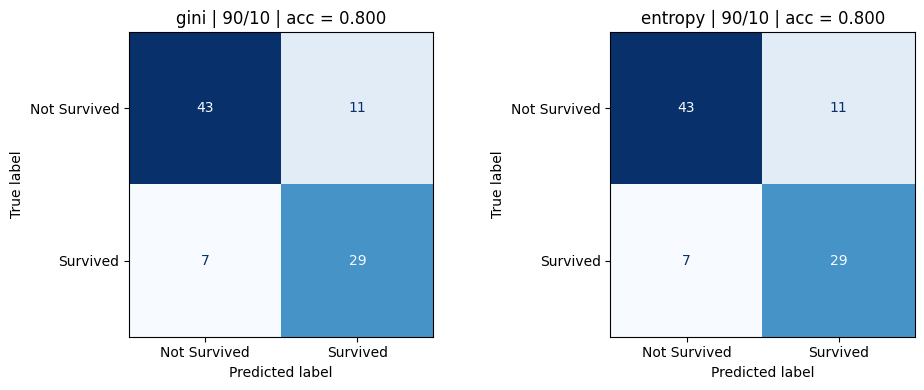

In [21]:
evaluate_partition(0.10, "90/10")

**Partition 2: 80% training / 20% testing**

gini | 80/20 | Accuracy = 0.7542
[[83 22]
 [22 52]] 

entropy | 80/20 | Accuracy = 0.7709
[[84 21]
 [20 54]] 



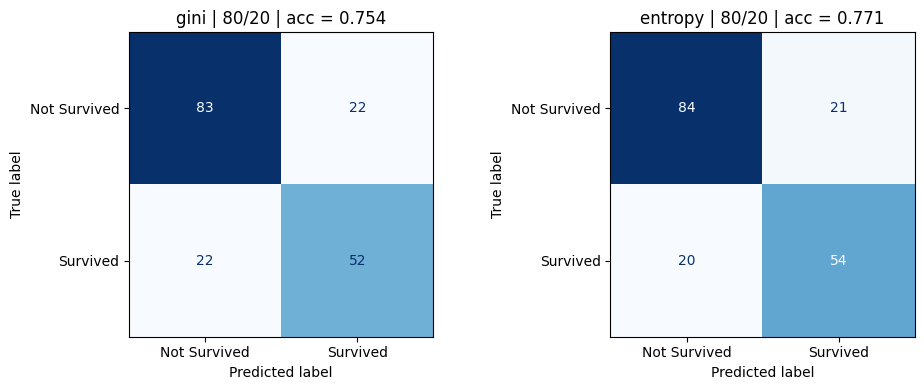

In [22]:
evaluate_partition(0.20, "80/20")

**Partition 3: 70% training / 30% testing**

gini | 70/30 | Accuracy = 0.7463
[[127  30]
 [ 38  73]] 

entropy | 70/30 | Accuracy = 0.7687
[[132  25]
 [ 37  74]] 



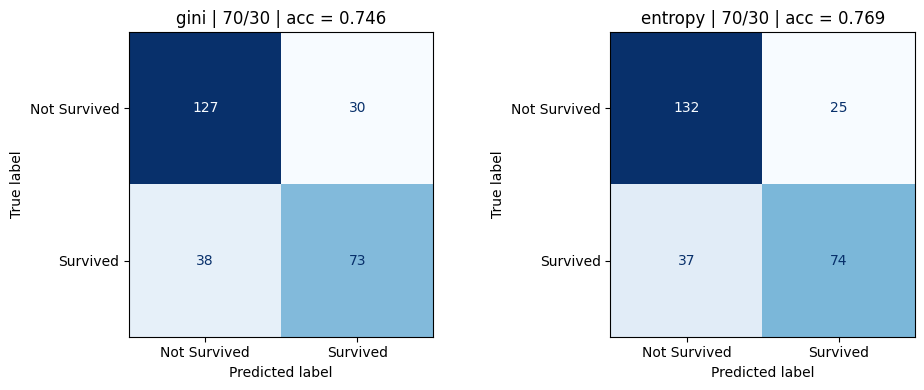

In [23]:
evaluate_partition(0.30, "70/30")

**Step 3: Summary tables.** One table for each attribute selection measure.

In [24]:
labels = ["90/10", "80/20", "70/30"]
columns = ["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"]

for crit, title in [("entropy", "Information Gain (Entropy)"), ("gini", "Gini index")]:
    table = pd.DataFrame([[round(results[(crit, l)], 4) for l in labels]],
                         index=["Accuracy"], columns=columns)
    print(f"Attribute selection measure: {title}")
    display(table)

Attribute selection measure: Information Gain (Entropy)


,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8,0.7709,0.7687


Attribute selection measure: Gini index


,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8,0.7542,0.7463


**Step 4: Best measure for each partition and overall.**

In [25]:
for l in labels:
    g, e = results[("gini", l)], results[("entropy", l)]
    winner = "Tie" if abs(g - e) < 1e-12 else ("Entropy" if e > g else "Gini")
    print(f"{l}: Gini = {g:.4f} | Entropy = {e:.4f} -> best: {winner}")

avg = {c: sum(results[(c, l)] for l in labels) / len(labels) for c in ["gini", "entropy"]}
print("\nAverage accuracy over all partitions:")
print({c: round(a, 4) for c, a in avg.items()})

90/10: Gini = 0.8000 | Entropy = 0.8000 -> best: Tie
80/20: Gini = 0.7542 | Entropy = 0.7709 -> best: Entropy
70/30: Gini = 0.7463 | Entropy = 0.7687 -> best: Entropy

Average accuracy over all partitions:
{'gini': 0.7668, 'entropy': 0.7799}


**Step 5: The final Decision Tree of the best model.** The best model is the one with the highest accuracy. When two models have the same accuracy, the one whose measure has the higher average accuracy across all partitions is selected. Only the first 4 levels are drawn so the tree stays readable.

Best model: entropy | 90/10 | Accuracy = 0.8


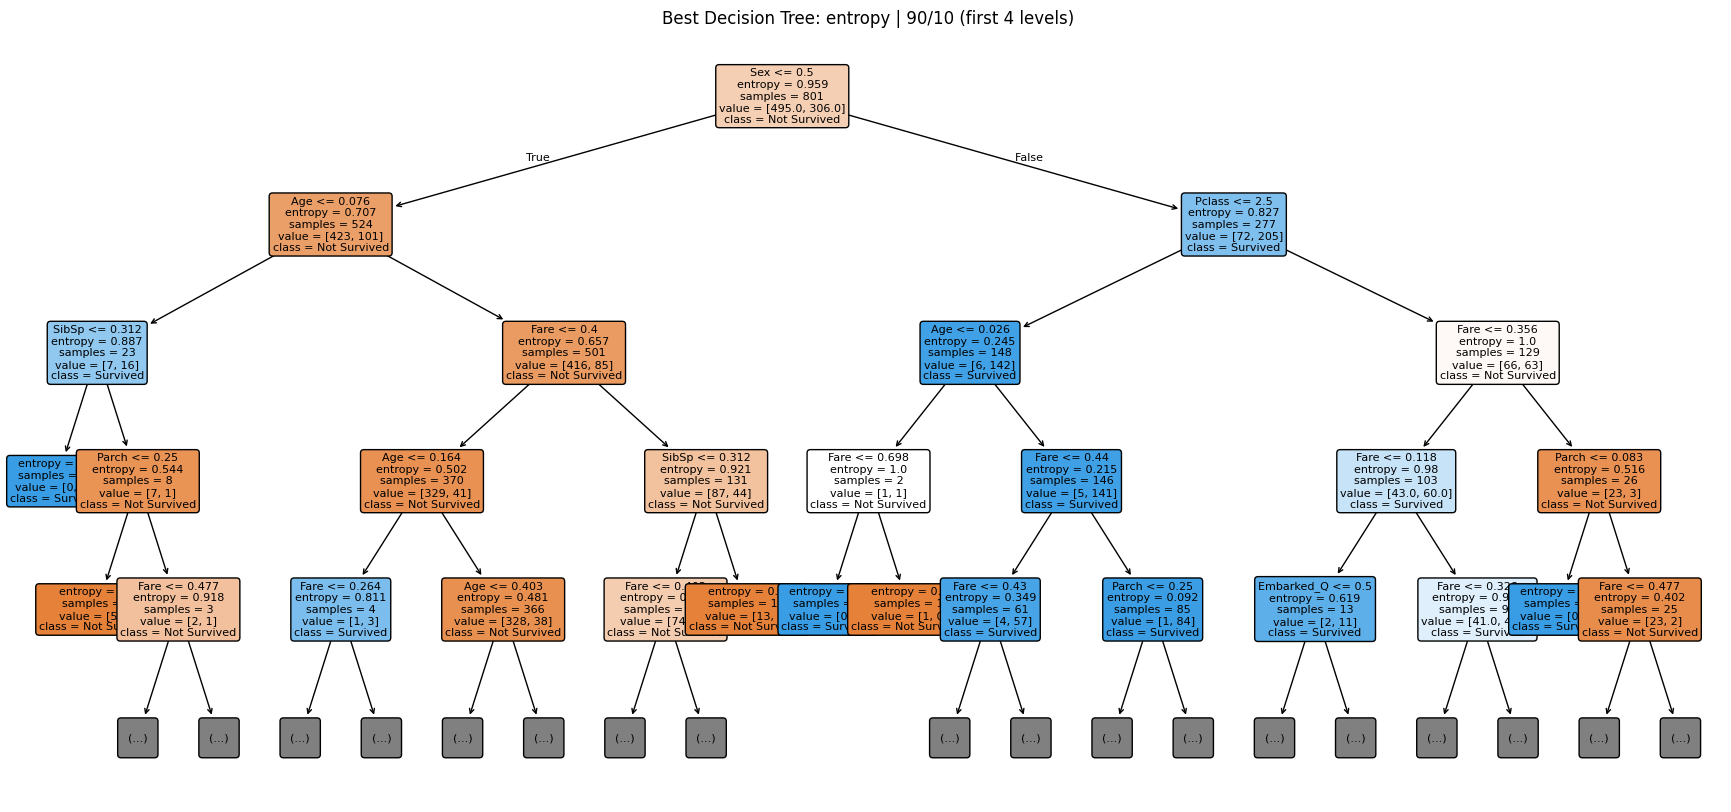

In [26]:
sizes = {"90/10": 0.10, "80/20": 0.20, "70/30": 0.30}
best_crit, best_split = max(results, key=lambda k: (results[k], avg[k[0]]))
print("Best model:", best_crit, "|", best_split, "| Accuracy =", round(results[(best_crit, best_split)], 4))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=sizes[best_split], random_state=42)
best_model = DecisionTreeClassifier(criterion=best_crit, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(best_model, feature_names=X.columns, class_names=["Not Survived", "Survived"],
          filled=True, rounded=True, fontsize=8, max_depth=4)
plt.title(f"Best Decision Tree: {best_crit} | {best_split} (first 4 levels)")
plt.show()

### Discussion of the classification results

**Best measure for each partition:**
- **90/10:** Gini and Entropy are tied (accuracy = 0.80), and both produced the same confusion matrix.
- **80/20:** Entropy is better (0.7709 vs 0.7542 for Gini).
- **70/30:** Entropy is better (0.7687 vs 0.7463 for Gini).

**Best measure overall:** Entropy. It was better than or equal to Gini in every partition, and its average accuracy (0.780) is higher than Gini's (0.767).

**Best model:** Entropy with the 90/10 partition (accuracy = 0.80, confusion matrix [[43, 11], [7, 29]]). Accuracy decreases slightly when the test set gets larger, because less data is left for training. However, the 90/10 test set contains only 90 rows, so its accuracy is less stable than the other partitions.

**The final tree:** The root of the tree splits on `Sex`, which means it is the most informative attribute. Among females, the next split is on `Pclass`: first and second class females almost all survived. Among males, the next split is on `Age`: young boys survived more than adult men. This shows that sex, ticket class and age are the strongest predictors of survival. The Age and Fare thresholds look small (for example 0.076) because these features were normalized in the preprocessing step.

##6.2 Clustering(K-Means)

In this section, the K-Means clustering algorithm is applied to the preprocessed dataset using three different values of K (2, 3, and 4). The results are evaluated using the Elbow method (WCSS) and the Silhouette coefficient. Cluster visualizations and cluster profiles are also examined to compare the results and interpret the characteristics of the resulting groups.

In [27]:
from sklearn.cluster import KMeans

# Apply K-Means using three different values of K
k_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)

    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    print(f"K = {k}")
    print(f"Number of clusters: {len(set(labels))}")
    print("-" * 30)

K = 2
Number of clusters: 2
------------------------------
K = 3
Number of clusters: 3
------------------------------
K = 4
Number of clusters: 4
------------------------------


#### Justification for Selecting K Values

Three candidate values of K (2, 3, and 4) were selected to compare different levels of clustering granularity. K = 2 represents a simpler partition, K = 3 provides an intermediate level of detail, and K = 4 examines whether additional clusters reveal more meaningful groupings in the dataset. These values will be evaluated using the Elbow Method and Silhouette Coefficient to help determine the most suitable number of clusters.

In [28]:
from sklearn.metrics import silhouette_score
import pandas as pd

clustering_results = []

for k in k_values:
    model = kmeans_models[k]
    labels = cluster_labels[k]

    clustering_results.append({
        "K": k,
        "Inertia (WCSS)": model.inertia_,
        "Silhouette Score": silhouette_score(X, labels)
    })

results_df = pd.DataFrame(clustering_results)

display(results_df.round(4))

,K,Inertia (WCSS),Silhouette Score
0,2,789.5228,0.3966
1,3,606.1515,0.4123
2,4,466.1330,0.4380


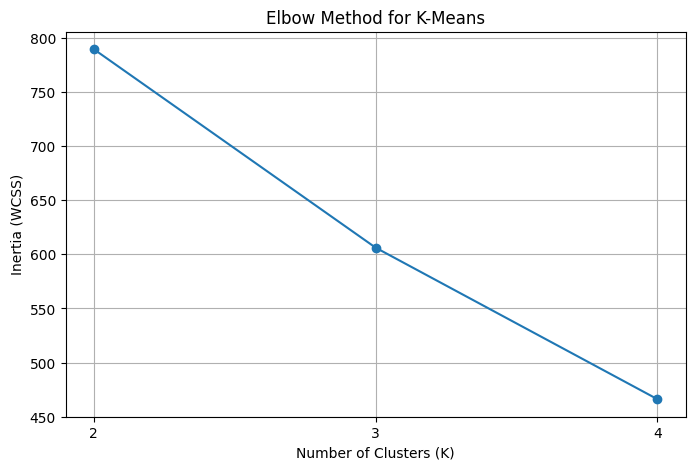

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["K"],
    results_df["Inertia (WCSS)"],
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

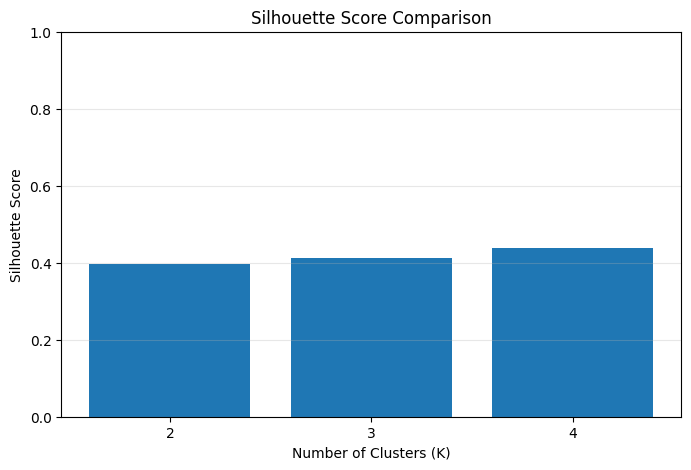

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["K"].astype(str),
    results_df["Silhouette Score"]
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

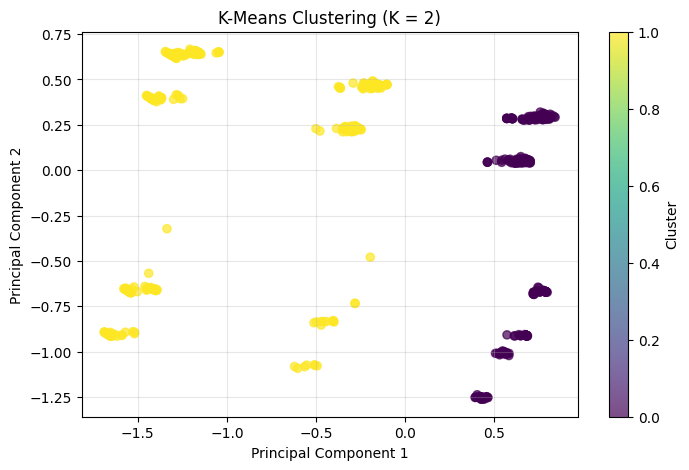

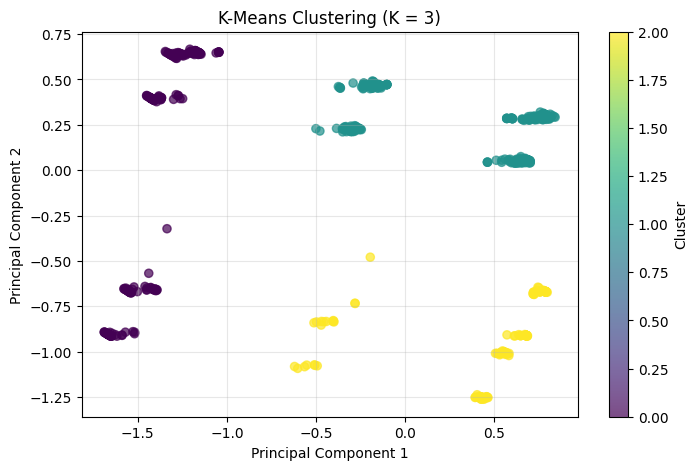

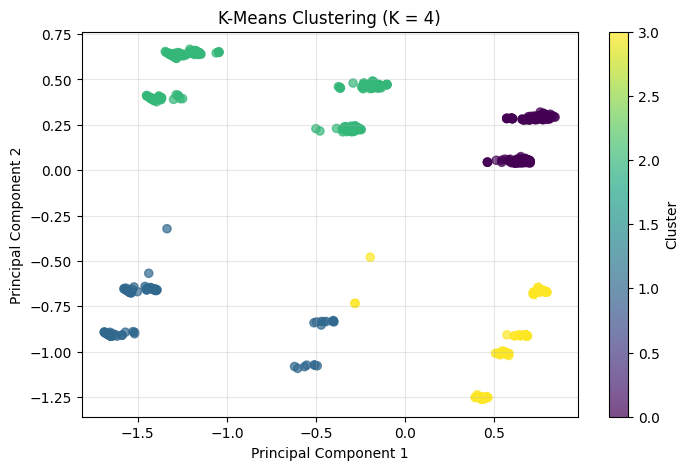

In [32]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce the data to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot clusters for each K value
for k in k_values:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=cluster_labels[k],
        cmap="viridis",
        s=35,
        alpha=0.7
    )

    plt.title(f"K-Means Clustering (K = {k})")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(True, alpha=0.3)
    plt.show()

In [33]:
# Analyze the size and characteristics of each cluster

for k in k_values:
    print(f"\n{'=' * 15} K = {k} {'=' * 15}")

    labels = cluster_labels[k]

    # Calculate the number of passengers in each cluster
    cluster_sizes = pd.Series(labels).value_counts().sort_index()
    print("\nCluster Sizes:")
    display(cluster_sizes.rename("Number of Passengers").to_frame())

    # Calculate the mean of each feature within each cluster
    cluster_profile = X.groupby(labels).mean().round(3)

    print("\nCluster Characteristics (Mean Values):")
    display(cluster_profile)


=============== K = 2 ===============

Cluster Sizes:


,Number of Passengers
0,491
1,400



Cluster Characteristics (Mean Values):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3.00,0.293,0.306,0.077,0.066,0.208,0.134,0.147,0.719
1,1.46,0.425,0.427,0.051,0.061,0.561,0.255,0.012,0.732



=============== K = 3 ===============

Cluster Sizes:


...

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1.000,0.435,0.476,0.052,0.059,0.774,0.394,0.009,0.597
1,2.683,0.300,0.334,0.076,0.070,0.249,0.000,0.000,1.000
2,2.873,0.411,0.290,0.050,0.050,0.194,0.525,0.475,0.000



=============== K = 4 ===============

Cluster Sizes:


,Number of Passengers
0,353
1,104
2,293
3,141



Cluster Characteristics (Mean Values):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3.000,0.249,0.315,0.088,0.073,0.222,0.000,0.000,1.0
1,1.163,0.490,0.443,0.054,0.058,0.778,0.981,0.019,0.0
2,1.560,0.399,0.421,0.051,0.063,0.488,0.000,0.000,1.0
3,2.979,0.411,0.290,0.047,0.045,0.171,0.468,0.532,0.0


In [35]:
final_comparison = results_df.copy()

final_comparison["Silhouette Rank"] = (
    final_comparison["Silhouette Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

final_comparison["Elbow Interpretation"] = [
    "WCSS decreases",
    "WCSS decreases",
    "WCSS decreases"
]

display(final_comparison.round(4))

,K,Inertia (WCSS),Silhouette Score,Silhouette Rank,Elbow Interpretation
0,2,789.5228,0.3966,3,WCSS decreases
1,3,606.1515,0.4123,2,WCSS decreases
2,4,466.1330,0.4380,1,WCSS decreases


6.2 Clustering Evaluation and Comparison

Comparison of K-Means Results

The K-Means algorithm was evaluated using three different values of K: 2, 3, and 4. The results were compared using the Elbow method, the Silhouette coefficient, and visual representations of the resulting clusters.

The WCSS values decreased from 789.5228 for K = 2 to 606.1515 for K = 3 and 466.1330 for K = 4. This decrease indicates that the observations became closer to their assigned cluster centers as the number of clusters increased. However, the Elbow plot did not show a clearly defined turning point among the three tested values, so it did not provide a conclusive optimal K.

The Silhouette scores were 0.3966 for K = 2, 0.4123 for K = 3, and 0.4380 for K = 4. K = 4 achieved the highest score, indicating the best relative cluster compactness and separation among the tested options. Nevertheless, the score does not indicate perfect separation between all clusters.

Interpretation of Cluster Characteristics

For K = 2, the algorithm divided the 891 passengers into two groups containing 491 and 400 passengers. The first group had an average Pclass value of 3.00, while the second had an average value of 1.46. This suggests a distinction between passengers associated mainly with third class and passengers associated more strongly with first and second class.

For K = 3, the clusters contained 216, 517, and 158 passengers. The first cluster was strongly associated with first-class passengers. The second was mainly associated with third-class passengers, while the third showed a different distribution of embarkation indicators. This solution provided more detailed groupings than K = 2.

For K = 4, the clusters contained 353, 104, 293, and 141 passengers. The first cluster was associated mainly with third-class passengers who embarked at Southampton. The second was associated mainly with first-class passengers and had the highest average Fare value among the four groups. The third was associated with passengers who embarked at Southampton and had a lower average Pclass value than the first cluster. The fourth was associated mainly with third-class passengers and passengers who embarked at Cherbourg or Queenstown.

The colored PCA plots provide a two-dimensional view of the cluster assignments for each value of K. They help illustrate how the algorithm separates observations into groups, although the plots represent the data using only two principal components.

Conclusion

Based on the evaluation results, K = 4 is the preferred option according to the Silhouette coefficient because it achieved the highest score of 0.4380. It also produced a more detailed division of passengers into four groups. However, the Elbow method did not identify a clearly defined optimal K among the tested values. Therefore, the results support K = 4 as the best option according to Silhouette, but they do not establish unanimous agreement between the two evaluation methods.

The cluster profiles also show that K-Means grouped passengers according to similarities in features such as passenger class, fare, and embarkation port. These findings demonstrate how clustering can reveal patterns in the dataset without using the Survived target variable during training.